# **Forward modeling: conditions on K**
### - Full observation of K, comparison with numerical simulation and deterministic surrogate model
### - Sparse observation of K, comparison with deterministic surrogate model
### - Low-resolution of K, comparison with deterministic surrogate model

env: CUDA_VISIBLE_DEVICES=1
cuda


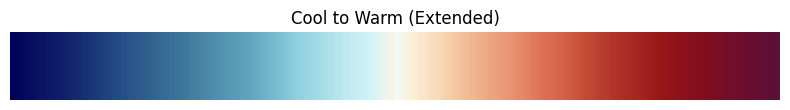

In [1]:
%env CUDA_VISIBLE_DEVICES = 1
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

from ConditionalDiffusionGeneration.forward_model.ufno import Net3d
from ConditionalDiffusionGeneration.forward_model.dataset_prepare import OperatorDataset, load_hdf5

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    dev = "cuda"
else:
    dev = "cpu"

device = torch.device(dev)
print(device)

from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]


rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)


x = rgb_points[:, 0]

r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]

colors = list(zip(x, zip(r, g, b)))

mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)
gradient = np.linspace(0, 1, 256).reshape(1, -1)
plt.figure(figsize=(8, 1.2))
plt.imshow(gradient, aspect='auto', cmap=mycmap)
plt.axis("off")
plt.title("Cool to Warm (Extended)")
plt.tight_layout()
plt.show()

### Load Unconditional Model

In [2]:
u_net_model = create_model(image_size= 64,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4,2,1",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_unet_experiment1/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

loaded unet


### Conditional Operator and Noise

In [3]:
operator =  get_operator(name='cartesian_superresolution',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1900,
                        ds_size=4,
                        vanilla_flag=False,
                        )

Simulation data loaded, with shape (64, 64, 64, 3)


In [4]:
noiser = get_noise(sigma=0.0, name='gaussian')

### Conditioning Method

In [5]:
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

### Sampler

In [6]:
sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

### Generate Samples

In [7]:
no_of_samples = 10
time_length = 64
latent_size = 256

In [8]:
x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [9]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")

Generated latents shape: torch.Size([10, 64, 256])


### Decoding latents to flow fields

In [10]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [11]:
# gen_latents = torch.load('conditional_outputs/pts/generated_latents_Cart8xSR.pt')
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'forward_outputs/pts/CNF_out_low_res(4).pt')    # ! mind to change

CNF output shape: torch.Size([10, 64, 64, 64, 3])


# **Full observation**

In [4]:
full = torch.load('forward_outputs/pts/CNF_out_full.pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {full.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


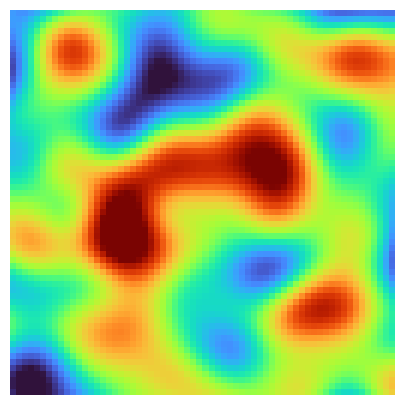

In [5]:
plt.figure(figsize=(5, 5))
plt.imshow(ref[0, :, :, -1], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Ref_K.pdf', bbox_inches='tight')

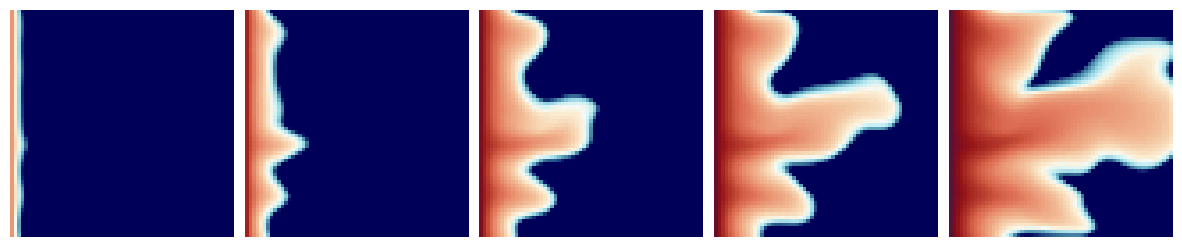

In [6]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(ref[t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('forward_outputs/figs/Ref_Sg.pdf', bbox_inches='tight')

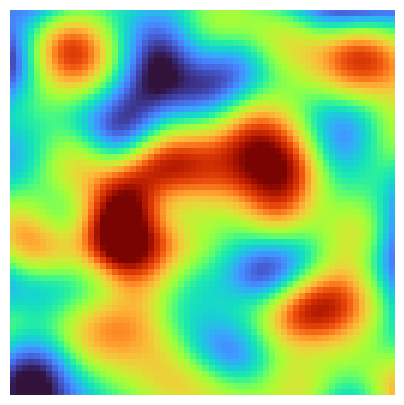

In [67]:
full_k = np.mean(full[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(full_k[4, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_full_K_4.pdf', bbox_inches='tight')

Full SG shape: (10, 64, 64, 64)


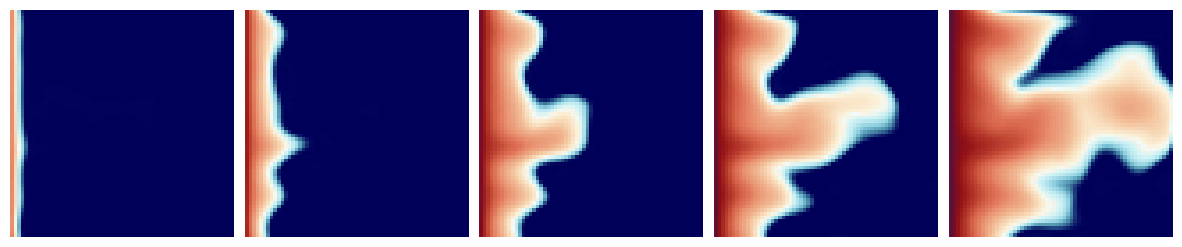

In [12]:
full_sg = full[..., 1]
print(f"Full SG shape: {full_sg.shape}")
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(full_sg[4, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/Gene_full_Sg_4.pdf', bbox_inches='tight')

***UNFO testing***

In [5]:
ufno = Net3d(10, 10, 10, 36).to(device)
ufno.load_state_dict(torch.load('../../../ConditionalDiffusionGeneration/forward_model/checkpoint_ufno_sat.pth', map_location=device)['model_state_dict'])
ufno.eval()
print('ufno loaded')

ufno loaded


In [6]:
ufno_dataset = OperatorDataset(load_hdf5('../../../Dataset/Cartesian_simple.hdf5'), ps_flag='sat')
print(f"UFNO dataset length: {len(ufno_dataset)}")

>>>>> Loading data from /ehome/zhao/nf/CoNFiLD/Dataset/Cartesian_simple.hdf5
>>>>> Loaded H5PY permeability with shape (2000, 64, 64)
>>>>> Loaded H5PY permeability_log with shape (2000, 64, 64)
>>>>> Loaded H5PY pressure with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY saturation with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY time_step with shape (2000, 64)
>>>>> Loading min-max values from perm_min_max.json
>>>>> Loading min-max values from ts_min_max.json
>>>>> Loading min-max values from sat_min_max.json
>>>>> Loading min-max values from pre_min_max.json
>>>>> Loaded Dataset, x shape: torch.Size([2000, 64, 64, 64, 2]), y shape: torch.Size([2000, 64, 64, 64])
UFNO dataset length: 2000


In [7]:
# ! Note ufno shape: <b, x, y, t, c>
ufno_input, ufno_label = ufno_dataset[1900]
ufno_k = ufno_input[:, :, 0, 0]
ufno_k = ufno_dataset._min_max_denormalize(ufno_k, 'perm_min_max.json')
print(f"UFNO input shape: {ufno_input.shape}, output shape: {ufno_label.shape}, k shape: {ufno_k.shape}")

UFNO input shape: torch.Size([64, 64, 64, 2]), output shape: torch.Size([64, 64, 64]), k shape: torch.Size([64, 64])


In [8]:
with torch.no_grad():
    ufno_pred = ufno(ufno_input.unsqueeze(0).to(device))
ufno_pred = ufno_pred.cpu().numpy()
ufno_pred = ufno_dataset._min_max_denormalize(ufno_pred, 'sat_min_max.json').squeeze(0)
print(f"UFNO prediction shape: {ufno_pred.shape}")

UFNO prediction shape: (64, 64, 64)


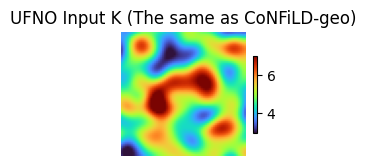

In [9]:
plt.figure(figsize=(2, 2))
plt.imshow(ufno_k, cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.colorbar(shrink=0.5)
plt.title('UFNO Input K (The same as CoNFiLD-geo)')
plt.show()

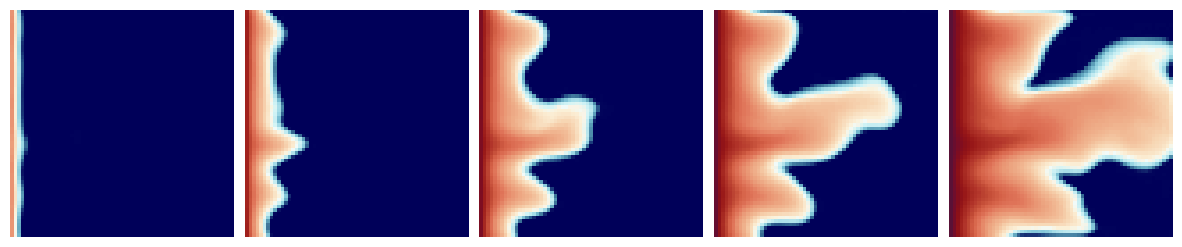

In [39]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/UFNO_full_Sg.pdf', bbox_inches='tight')

In [10]:
def compute_temporal_ssim(reference_all, predictions):
    reference = reference_all[:, :, :, 1]
    ssim_values = []
    if len(predictions.shape) == 4:
        print('Computing SSIM for CoNFiLD-geo')
        for i in range(predictions.shape[0]):
            ssim_t_values = []
            for t in range(predictions.shape[1]):
                ssim_value = ssim(reference[t, :, :], predictions[i, t, :, :], data_range=reference[t, :, :].max() - reference[t, :, :].min())
                ssim_t_values.append(ssim_value)
            ssim_values.append(np.array(ssim_t_values))
        return np.array(ssim_values)

    elif len(predictions.shape) == 3:
        print('Computing SSIM for UFNO')
        for t in range(predictions.shape[-1]):
            ssim_value = ssim(reference[t, :, :], predictions[:, :, t], data_range=reference[t, :, :].max() - reference[t, :, :].min())
            ssim_values.append(ssim_value)
        return np.array(ssim_values)
    else:
        raise ValueError("Predictions must be 3D or 4D.")

def compute_temporal_rmse(reference_all, predictions):
    reference = reference_all[:, :, :, 1]
    ssim_values = []
    if len(predictions.shape) == 4:
        print('Computing SSIM for CoNFiLD-geo')
        for i in range(predictions.shape[0]):
            ssim_t_values = []
            for t in range(predictions.shape[1]):
                ssim_value = np.sqrt((reference[t, :, :] -  predictions[i, t, :, :])**2).mean()
                ssim_t_values.append(ssim_value)
            ssim_values.append(np.array(ssim_t_values))
        return np.array(ssim_values)

    elif len(predictions.shape) == 3:
        print('Computing SSIM for UFNO')
        for t in range(predictions.shape[-1]):
            ssim_value = np.sqrt((reference[t, :, :] - predictions[:, :, t])**2).mean()
            ssim_values.append(ssim_value)
        return np.array(ssim_values)
    else:
        raise ValueError("Predictions must be 3D or 4D.")

def plot_perm_mean_std(data, color, name):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    plt.plot(range(data.shape[-1]), mean, color=color, linewidth=2, label=name, ls='-')
    plt.fill_between(range(data.shape[-1]), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')

In [13]:
ssim_gen = compute_temporal_ssim(ref, full_sg)
ssim_ufno = compute_temporal_ssim(ref, ufno_pred)
rmse_gen = compute_temporal_rmse(ref, full_sg)
rmse_ufno = compute_temporal_rmse(ref, ufno_pred)
print(f"SSIM for CoNFiLD-geo shape: {ssim_gen.shape}, UFNO shape: {ssim_ufno.shape}")
print(f"RMSE for CoNFiLD-geo shape: {rmse_gen.shape}, UFNO shape: {rmse_ufno.shape}")

Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
SSIM for CoNFiLD-geo shape: (10, 64), UFNO shape: (64,)
RMSE for CoNFiLD-geo shape: (10, 64), UFNO shape: (64,)


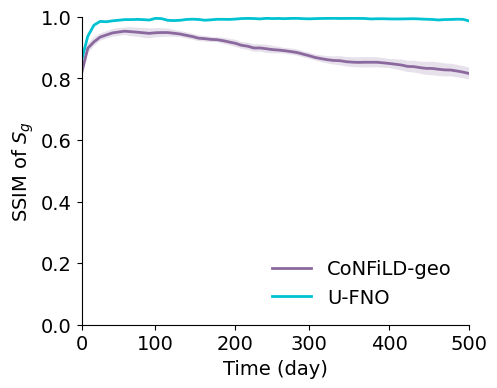

In [34]:
plt.figure(figsize=(5, 4))
plot_perm_mean_std(ssim_gen, '#8B699EFF', 'CoNFiLD-geo')
plt.plot(ssim_ufno, color='#00c2d1', linewidth=2, label='U-FNO', ls='-')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(0, 1)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('SSIM of $S_g$', fontsize=14)
plt.legend(fontsize=14, loc='lower right', frameon=False)

plt.savefig('forward_outputs/figs/full_compare_ssim.pdf', bbox_inches='tight')

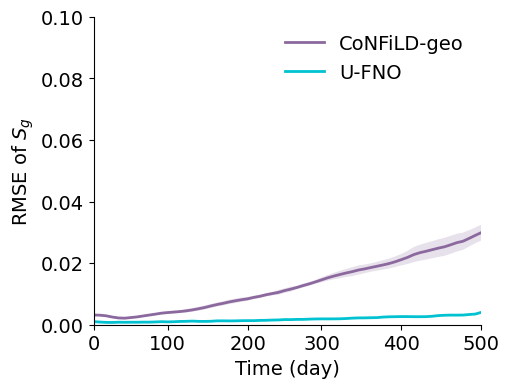

In [35]:
plt.figure(figsize=(5, 4))

plot_perm_mean_std(rmse_gen, '#8B699EFF', 'CoNFiLD-geo')
plt.plot(rmse_ufno, color='#00c2d1', linewidth=2, label='U-FNO', ls='-')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(0, 0.10)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('RMSE of $S_g$', fontsize=14)
plt.legend(fontsize=14, loc='upper right', frameon=False)

plt.savefig('forward_outputs/figs/full_compare_rmse.pdf', bbox_inches='tight')

# **Low-resolution K**

In [12]:
low_res_4 = torch.load('forward_outputs/pts/CNF_out_low_res(4).pt', map_location='cpu').detach().numpy()
low_res_8 = torch.load('forward_outputs/pts/CNF_out_low_res(8).pt', map_location='cpu').detach().numpy()
low_res_16 = torch.load('forward_outputs/pts/CNF_out_low_res(16).pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {low_res_8.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


In [13]:
def downsample(numpy_array, ds_size):
    import torch.nn.functional as F
    ds_size = (ds_size, ds_size) if isinstance(ds_size, int) else tuple(ds_size)
    to_tensor = torch.from_numpy(numpy_array).unsqueeze(0).unsqueeze(0)
    print(f"Before downsample shape: {to_tensor.shape}")
    ds_tensor = F.interpolate(to_tensor, size=ds_size, mode='nearest')
    print(f"After downsample shape: {ds_tensor.shape}")
    return ds_tensor.squeeze(0).squeeze(0).numpy()

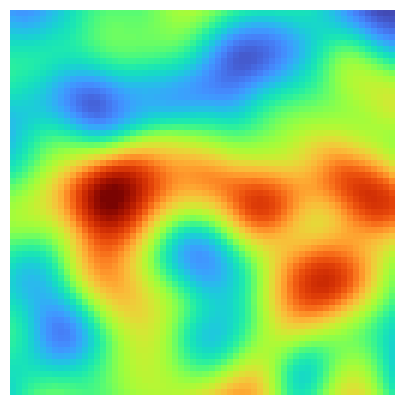

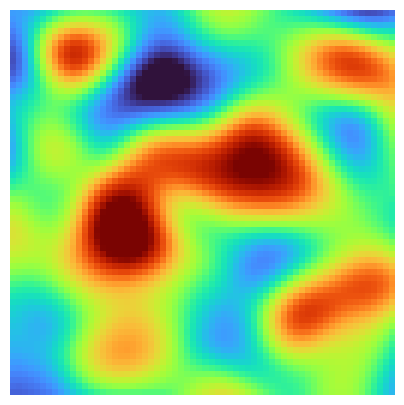

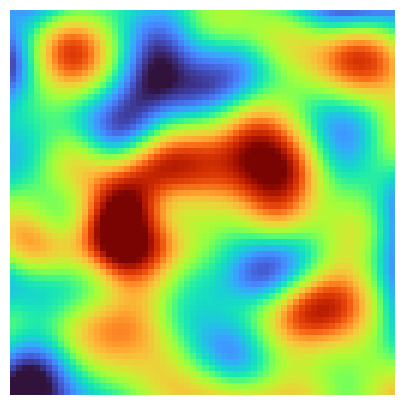

In [19]:
low_res_4_k = np.mean(low_res_4[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(low_res_4_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(4)_K.pdf', bbox_inches='tight')

low_res_8_k = np.mean(low_res_8[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(low_res_8_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(8)_K.pdf', bbox_inches='tight')

low_res_16_k = np.mean(low_res_16[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(low_res_16_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(16)_K.pdf', bbox_inches='tight')

Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 4, 4])
Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 8, 8])
Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 16, 16])


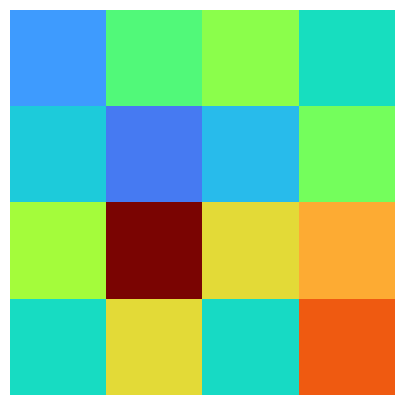

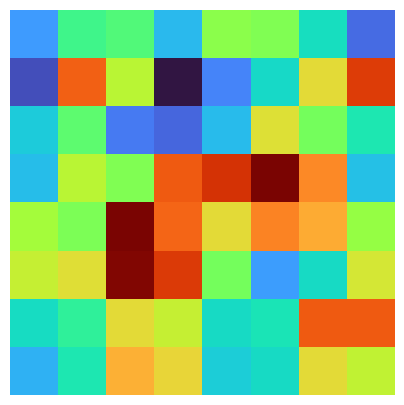

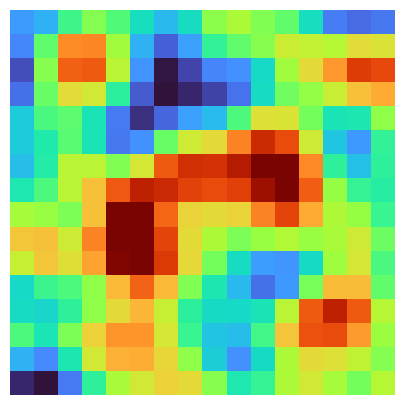

In [20]:
plt.figure(figsize=(5, 5))
plt.imshow(downsample(ref[0, :, :, -1], 4), cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(4)_K_down.pdf', bbox_inches='tight')

plt.figure(figsize=(5, 5))
plt.imshow(downsample(ref[0, :, :, -1], 8), cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(8)_K_down.pdf', bbox_inches='tight')


plt.figure(figsize=(5, 5))
plt.imshow(downsample(ref[0, :, :, -1], 16), cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs/Gene_low_res(16)_K_down.pdf', bbox_inches='tight')

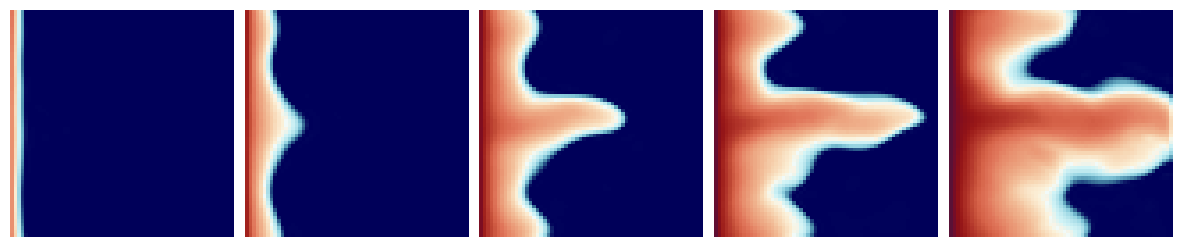

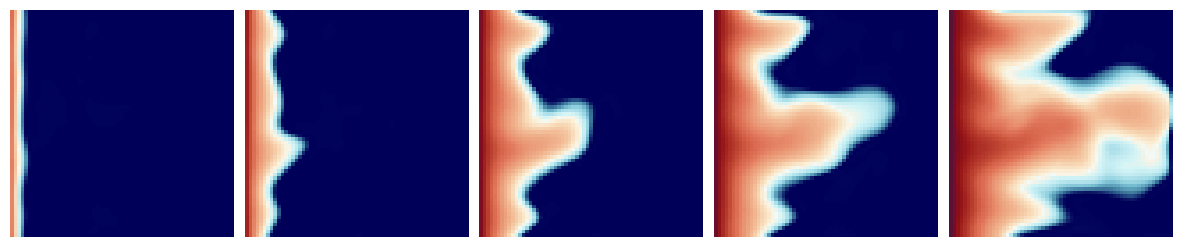

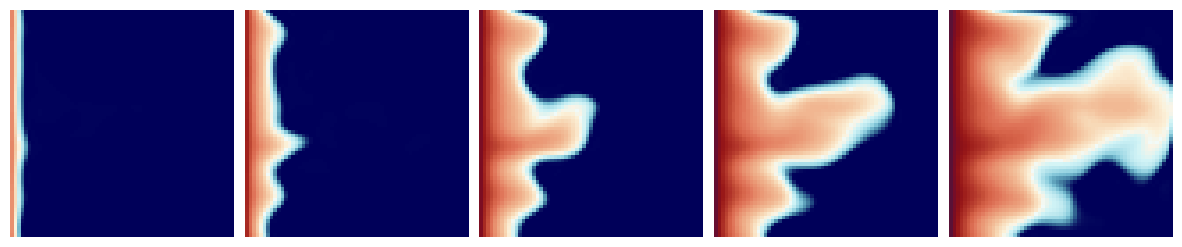

In [21]:
low_res_4_sg = low_res_4[..., 1]
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(low_res_4_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/Gene_low_res(4)_Sg.pdf', bbox_inches='tight')

low_res_8_sg = low_res_8[..., 1]
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(low_res_8_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/Gene_low_res(8)_Sg.pdf', bbox_inches='tight')

low_res_16_sg = low_res_16[..., 1]
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(low_res_16_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/Gene_low_res(16)_Sg.pdf', bbox_inches='tight')

In [22]:
ufno = Net3d(10, 10, 10, 36).to(device)
ufno.load_state_dict(torch.load('../../../ConditionalDiffusionGeneration/forward_model/checkpoint_ufno_sat.pth', map_location=device)['model_state_dict'])
ufno.eval()
print('ufno loaded')

ufno_dataset = OperatorDataset(load_hdf5('../../../Dataset/Cartesian_simple.hdf5'), ps_flag='sat')
print(f"UFNO dataset length: {len(ufno_dataset)}")

ufno loaded
>>>>> Loading data from /ehome/zhao/nf/CoNFiLD/Dataset/Cartesian_simple.hdf5
>>>>> Loaded H5PY permeability with shape (2000, 64, 64)
>>>>> Loaded H5PY permeability_log with shape (2000, 64, 64)
>>>>> Loaded H5PY pressure with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY saturation with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY time_step with shape (2000, 64)
>>>>> Loading min-max values from perm_min_max.json
>>>>> Loading min-max values from ts_min_max.json
>>>>> Loading min-max values from sat_min_max.json
>>>>> Loading min-max values from pre_min_max.json
>>>>> Loaded Dataset, x shape: torch.Size([2000, 64, 64, 64, 2]), y shape: torch.Size([2000, 64, 64, 64])
UFNO dataset length: 2000


In [29]:
def ufno_predict(ds_size):
    up_perm = downsample(downsample(ref[0, :, :, -1], ds_size), 64)
    normed_perm = ufno_dataset._min_max_normalize(up_perm, 'perm_min_max.json')
    perm_tiled = np.tile(normed_perm[None, None, :, :], (1, 64, 1, 1))
    ts_tiled = np.tile(np.linspace(0, 1, 64)[None, :, None, None], (1, 1, 64, 64))
    # print(f"Perm tiled shape: {perm_tiled.shape}, ts tiled shape: {ts_tiled.shape}")
    ufno_input = torch.tensor(np.stack((perm_tiled, ts_tiled), axis=-1), dtype=torch.float32).permute(0, 2, 3, 1, 4)
    with torch.no_grad():
        ufno_pred = ufno(ufno_input.to(device))
    ufno_pred = ufno_pred.cpu().numpy()
    ufno_pred = ufno_dataset._min_max_denormalize(ufno_pred, 'sat_min_max.json').squeeze(0)
    print(f"UFNO prediction shape: {ufno_pred.shape}")
    return ufno_pred

In [30]:
ufno_pred_4 = ufno_predict(4)
ufno_pred_8 = ufno_predict(8)
ufno_pred_16 = ufno_predict(16)

Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 4, 4])
Before downsample shape: torch.Size([1, 1, 4, 4])
After downsample shape: torch.Size([1, 1, 64, 64])
>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)
Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 8, 8])
Before downsample shape: torch.Size([1, 1, 8, 8])
After downsample shape: torch.Size([1, 1, 64, 64])
>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)
Before downsample shape: torch.Size([1, 1, 64, 64])
After downsample shape: torch.Size([1, 1, 16, 16])
Before downsample shape: torch.Size([1, 1, 16, 16])
After downsample shape: torch.Size([1, 1, 64, 64])
>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)


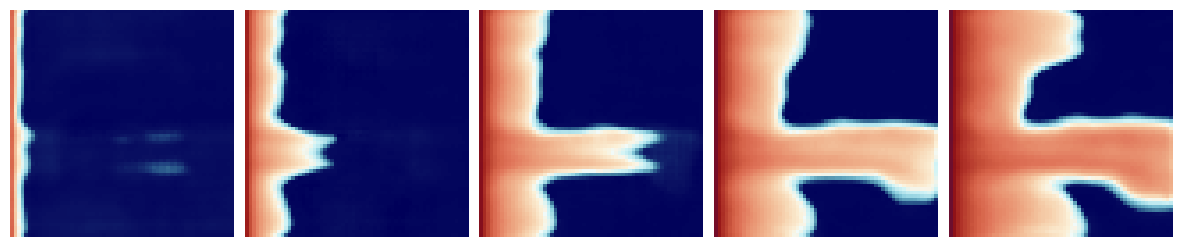

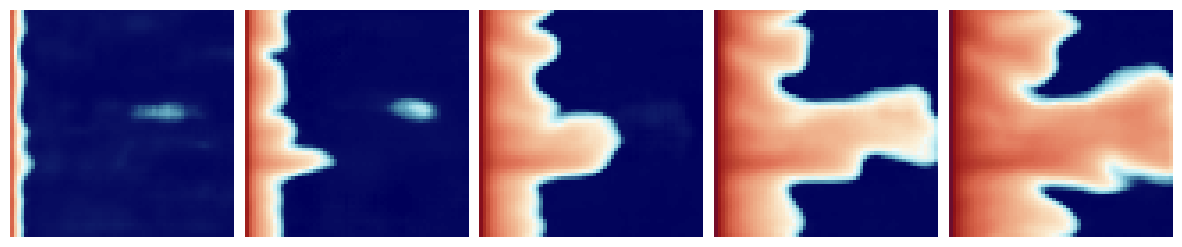

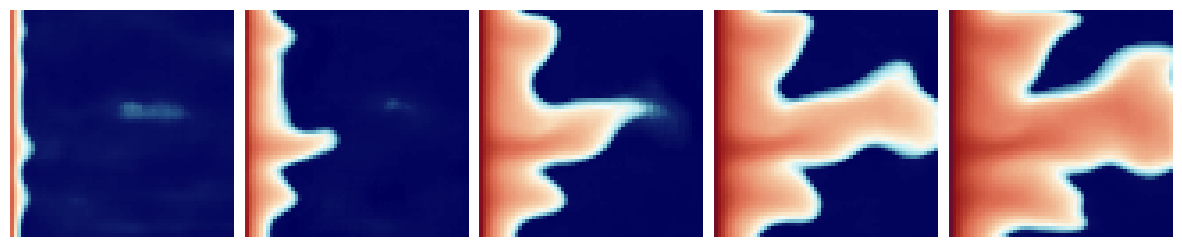

In [31]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_4[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/UFNO_low_res(4)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_8[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/UFNO_low_res(8)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_16[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs/UFNO_low_res(16)_Sg.pdf', bbox_inches='tight')

In [35]:
gen_list = [low_res_4_sg, low_res_8_sg, low_res_16_sg]
ufno_list = [ufno_pred_4, ufno_pred_8, ufno_pred_16]
def metric_wrapper():
    ssim_gen_list = []
    rmse_gen_list = []
    ssim_ufno_list = []
    rmse_ufno_list = []
    for gen, ufno_pred in zip(gen_list, ufno_list):
        ssim_gen = compute_temporal_ssim(ref, gen)
        rmse_gen = compute_temporal_rmse(ref, gen)
        ssim_ufno = compute_temporal_ssim(ref, ufno_pred)
        rmse_ufno = compute_temporal_rmse(ref, ufno_pred)

        ssim_gen_list.append(ssim_gen)
        rmse_gen_list.append(rmse_gen)
        ssim_ufno_list.append(ssim_ufno)
        rmse_ufno_list.append(rmse_ufno)
    ssim_gen_list = np.array(ssim_gen_list)
    rmse_gen_list = np.array(rmse_gen_list)
    ssim_ufno_list = np.array(ssim_ufno_list)
    rmse_ufno_list = np.array(rmse_ufno_list)
    print(f"SSIM for CoNFiLD-geo shape: {ssim_gen_list.shape}, UFNO shape: {ssim_ufno_list.shape}")
    print(f"RMSE for CoNFiLD-geo shape: {rmse_gen_list.shape}, UFNO shape: {rmse_ufno_list.shape}")
    return ssim_gen_list, rmse_gen_list, ssim_ufno_list, rmse_ufno_list

ssim_gen_list, rmse_gen_list, ssim_ufno_list, rmse_ufno_list = metric_wrapper()

Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
SSIM for CoNFiLD-geo shape: (3, 10, 64), UFNO shape: (3, 64)
RMSE for CoNFiLD-geo shape: (3, 10, 64), UFNO shape: (3, 64)


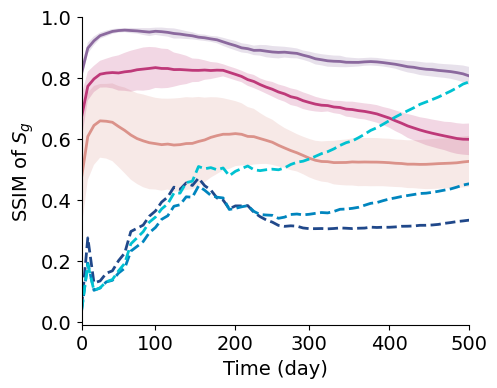

In [ ]:
colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = [r'CoNFiLD-geo ($4\times4$)', r'CoNFiLD-geo ($8\times8$)', r'CoNFiLD-geo ($16\times16$)']
labels_ufno = [r'UFNO ($4\times4$)', r'UFNO ($8\times8$)', r'UFNO ($16\times16$)']

plt.figure(figsize=(5, 4))

for i in range(3):
    plot_perm_mean_std(ssim_gen_list[i], colors_gen[i], labels_gen[i])
    plt.plot(range(64), ssim_ufno_list[i], color=colors_ufno[i], linewidth=2, label=labels_ufno[i], ls='--')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(top=1)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('SSIM of $S_g$', fontsize=14)
plt.savefig('forward_outputs/figs/low_res_ssim_sg.pdf', bbox_inches='tight')

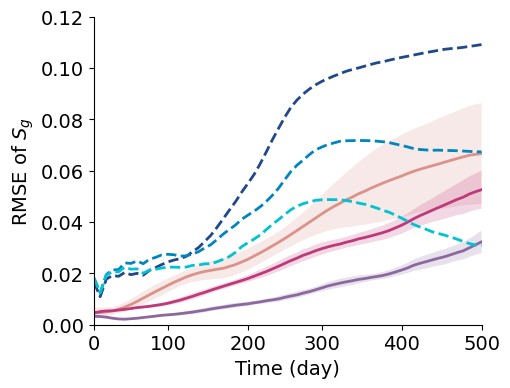

In [89]:
colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = [r'CoNFiLD-geo ($4\times4$)', r'CoNFiLD-geo ($8\times8$)', r'CoNFiLD-geo ($16\times16$)']
labels_ufno = [r'UFNO ($4\times4$)', r'UFNO ($8\times8$)', r'UFNO ($16\times16$)']

plt.figure(figsize=(5, 4))

for i in range(3):
    plot_perm_mean_std(rmse_gen_list[i], colors_gen[i], labels_gen[i])
    plt.plot(range(64), rmse_ufno_list[i], color=colors_ufno[i], linewidth=2, label=labels_ufno[i], ls='--')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(0, 0.12)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('RMSE of $S_g$', fontsize=14)
plt.savefig('forward_outputs/figs/low_res_rmse_sg.pdf', bbox_inches='tight')

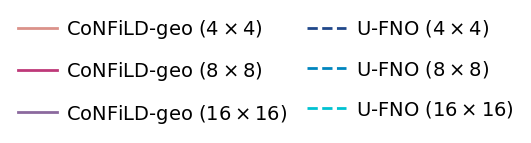

In [3]:
from matplotlib.lines import Line2D

colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = [r'CoNFiLD-geo ($4\times4$)', r'CoNFiLD-geo ($8\times8$)', r'CoNFiLD-geo ($16\times16$)']
labels_ufno = [r'U-FNO ($4\times4$)', r'U-FNO ($8\times8$)', r'U-FNO ($16\times16$)']

legend_elements = [
    # CoNFiLD-geo
    Line2D([0], [0], color=colors_gen[0], lw=2, ls='-', label=labels_gen[0]),
    Line2D([0], [0], color=colors_gen[1], lw=2, ls='-', label=labels_gen[1]),
    Line2D([0], [0], color=colors_gen[2], lw=2, ls='-', label=labels_gen[2]),
    # ufno
    Line2D([0], [0], color=colors_ufno[0], lw=2, ls='--', label=labels_ufno[0]),
    Line2D([0], [0], color=colors_ufno[1], lw=2, ls='--', label=labels_ufno[1]),
    Line2D([0], [0], color=colors_ufno[2], lw=2, ls='--', label=labels_ufno[2])
]

fig, ax = plt.subplots(figsize=(6, 1))
ax.axis('off')

# 添加图例：3 行 2 列
fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=2,
    frameon=False,
    handlelength=2,
    handletextpad=0.5,
    columnspacing=1,
    labelspacing=1,
    fontsize=14,
)

# plt.tight_layout()
plt.savefig('forward_outputs/figs/low_res_ssim_rmse_legends.pdf', bbox_inches='tight')
plt.show()

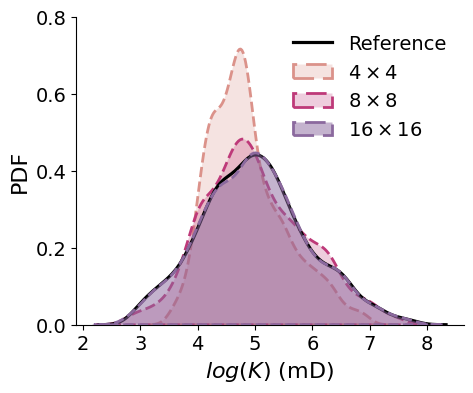

In [86]:
sr4_k_hist = np.mean(low_res_4_k, axis=0)
sr8_k_hist = np.mean(low_res_8_k, axis=0)
sr16_k_hist = np.mean(low_res_16_k, axis=0)

plt.figure(figsize=(5, 4))
colors = ['#0499b4', '#00468c', '#ae002a']
import seaborn as sns
sns.kdeplot(ref[0, :, :, -1].flatten(), color='black', label='Reference', linewidth=2.3, fill=False, ls='-', alpha=1)
sns.kdeplot(sr4_k_hist.flatten(), color=colors_gen[0], label=r'$4\times4$', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr8_k_hist.flatten(), color=colors_gen[1], label=r'$8\times8$', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr16_k_hist.flatten(), color=colors_gen[2], label=r'$16\times16$', linewidth=2, fill=True, ls='--', zorder=10, alpha=0.5)
# plt.xlim(1.5, 6.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 0.8)
plt.yticks([0, 0.2, 0.4, 0.6, 0.8], fontsize=14)
plt.xlabel('$log(K)$ (mD)', fontsize=16)
plt.ylabel('PDF', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(fontsize=14, frameon=False, loc='upper right')
plt.savefig('forward_outputs/figs/low_res_k_hist.pdf', bbox_inches='tight')
plt.show()

*plot maps*

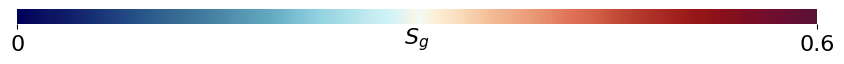

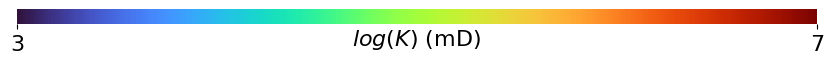

In [88]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.6)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(10, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([0, 0.6])
cbar.ax.set_xticklabels(["0", "0.6"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig('forward_outputs/figs/legends_sg.pdf', bbox_inches='tight')
plt.show()


# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=3, vmax=7)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(10, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([3, 7])
cbar.ax.set_xticklabels(["3", "7"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig('forward_outputs/figs/legends_k.pdf', bbox_inches='tight')
plt.show()

# **Sparse measurements of K**

In [21]:
operator =  get_operator(name='cartesian_sparse_measurement',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1900,
                        num_probed=123,
                        )

query_pts = operator.query_points
np.save('forward_outputs/npys/query_pts_(123).npy', np.array(query_pts))
print(query_pts)

noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # \lambda=1
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                        steps=1000,
                        noise_schedule="cosine",
                        model_mean_type="epsilon",
                        model_var_type="learned_range",
                        dynamic_threshold=False,
                        clip_denoised=True,
                        rescale_timesteps=False,
                        timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)


/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:76: UserWarning: Randomly generated 123 points for measurement, please check the results.
  warnings.warn(f"Randomly generated {num_probed} points for measurement, please check the results.")


Simulation data loaded, with shape (64, 64, 64, 3)
[(11, 20), (59, 12), (53, 14), (31, 52), (33, 5), (62, 9), (4, 26), (50, 18), (30, 56), (57, 24), (18, 30), (23, 38), (62, 50), (36, 6), (49, 12), (9, 47), (15, 21), (21, 33), (15, 56), (3, 59), (14, 50), (25, 57), (48, 3), (50, 17), (40, 36), (16, 60), (22, 31), (61, 48), (0, 7), (45, 61), (37, 58), (48, 40), (9, 35), (39, 3), (12, 12), (31, 38), (34, 39), (25, 22), (43, 51), (55, 39), (46, 21), (26, 2), (29, 27), (53, 44), (47, 25), (17, 45), (2, 41), (1, 13), (22, 16), (10, 16), (34, 47), (39, 52), (42, 40), (7, 20), (27, 34), (8, 37), (24, 4), (18, 22), (55, 6), (38, 28), (13, 1), (20, 19), (13, 23), (5, 48), (1, 62), (51, 62), (61, 57), (52, 31), (29, 60), (52, 51), (36, 4), (0, 46), (21, 36), (19, 7), (38, 24), (20, 13), (41, 54), (26, 58), (29, 28), (60, 53), (9, 24), (28, 11), (57, 8), (45, 29), (44, 42), (7, 27), (44, 16), (32, 5), (14, 1), (47, 49), (42, 32), (5, 11), (37, 33), (6, 51), (56, 18), (33, 28), (59, 19), (12, 59),

In [22]:
no_of_samples = 10
time_length = 64
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Measurement shape: torch.Size([64, 123])


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

...

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [23]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")

Generated latents shape: torch.Size([10, 64, 256])


In [24]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [25]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'forward_outputs/pts/CNF_out_sparse(123).pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


*Load PT files and plot...*

In [28]:
sparse20 = torch.load('forward_outputs/pts/CNF_out_sparse(20).pt', map_location='cpu').detach().numpy()
sparse41 = torch.load('forward_outputs/pts/CNF_out_sparse(41).pt', map_location='cpu').detach().numpy()
sparse123 = torch.load('forward_outputs/pts/CNF_out_sparse(123).pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {sparse20.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


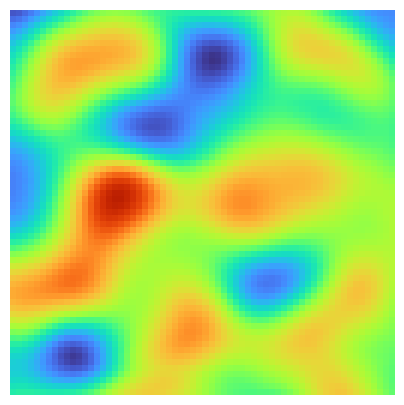

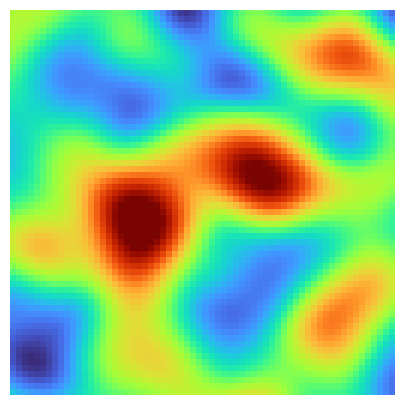

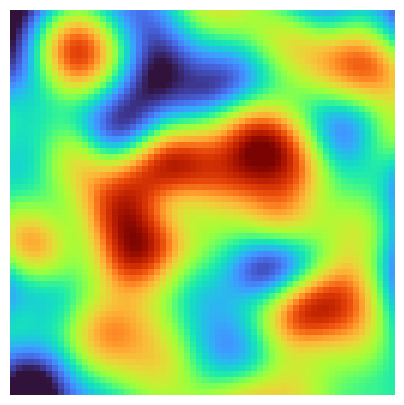

In [29]:
sparse20_k = np.mean(sparse20[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(sparse20_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(20)_K.pdf', bbox_inches='tight')

sparse41_k = np.mean(sparse41[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(sparse41_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(41)_K.pdf', bbox_inches='tight')

sparse123_k = np.mean(sparse123[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(sparse123_k[0, :, :], cmap='turbo', vmin=3, vmax=7)
plt.axis('off')
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(123)_K.pdf', bbox_inches='tight')

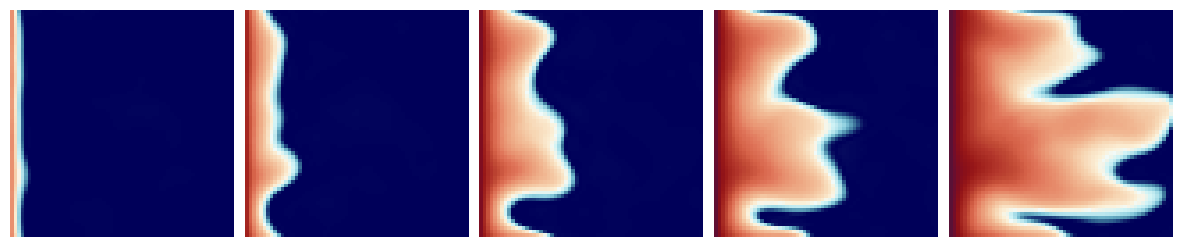

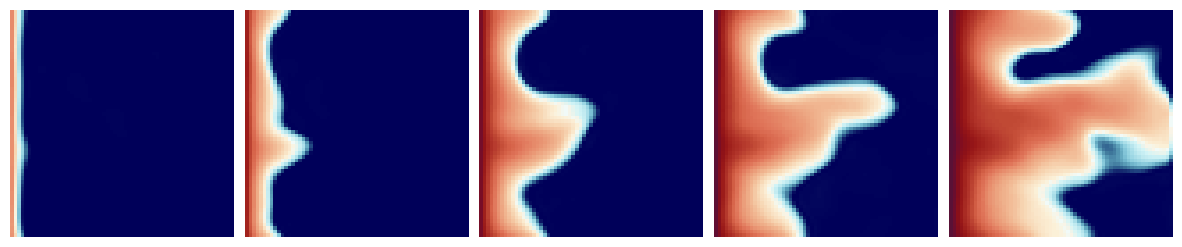

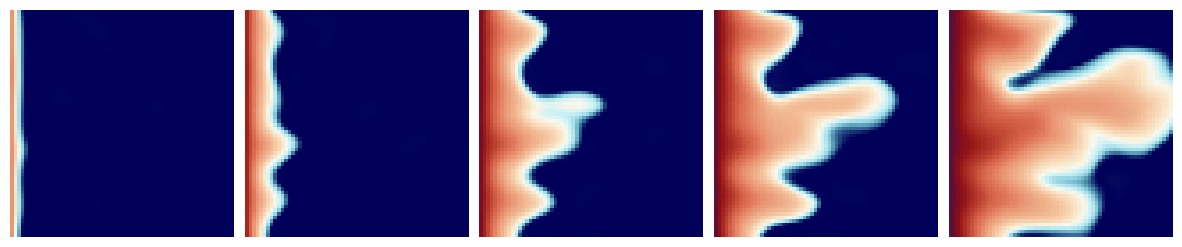

In [30]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse20[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(20)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse41[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(41)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse123[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(123)_Sg.pdf', bbox_inches='tight')

In [31]:
def query_points(image, pt_array):
    masked = np.full_like(image, np.nan)
    for (x, y) in pt_array:
        if 0 <= x < image.shape[0] and 0 <= y < image.shape[1]:
            masked[x, y] = image[x, y]
        else:
            print(f"Warning: Point ({x}, {y}) is out of bounds for the image of shape {image.shape}.")
    return masked

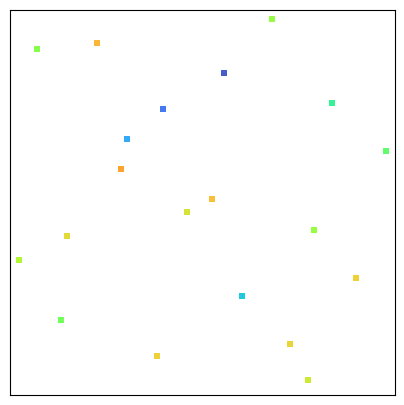

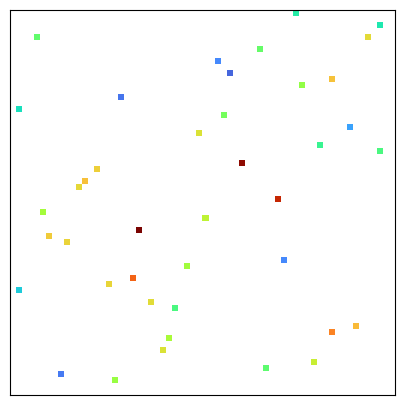

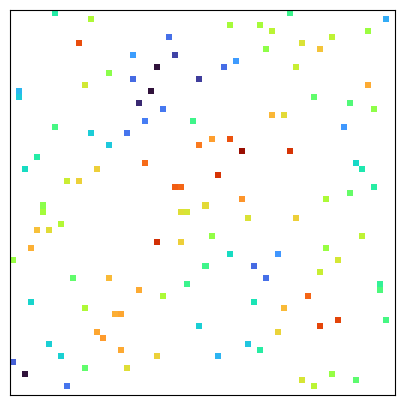

In [35]:
points20 = np.load('forward_outputs/npys/query_pts_(20).npy')
points41 = np.load('forward_outputs/npys/query_pts_(41).npy')
points123 = np.load('forward_outputs/npys/query_pts_(123).npy')

plt.figure(figsize=(5, 5))
plt.imshow(query_points(ref[0, :, :, -1], points20), cmap='turbo', vmin=3, vmax=7)
plt.axis('on')
plt.xticks([])
plt.yticks([])
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(20)_K_down.pdf', bbox_inches='tight')

plt.figure(figsize=(5, 5))
plt.imshow(query_points(ref[0, :, :, -1], points41), cmap='turbo', vmin=3, vmax=7)
plt.axis('on')
plt.xticks([])
plt.yticks([])
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(41)_K_down.pdf', bbox_inches='tight')


plt.figure(figsize=(5, 5))
plt.imshow(query_points(ref[0, :, :, -1], points123), cmap='turbo', vmin=3, vmax=7)
plt.axis('on')
plt.xticks([])
plt.yticks([])
plt.savefig('forward_outputs/figs_sparse/Gene_sparse(123)_K_down.pdf', bbox_inches='tight')

In [36]:
ufno = Net3d(10, 10, 10, 36).to(device)
ufno.load_state_dict(torch.load('../../../ConditionalDiffusionGeneration/forward_model/checkpoint_ufno_sat.pth', map_location=device)['model_state_dict'])
ufno.eval()
print('ufno loaded')

ufno_dataset = OperatorDataset(load_hdf5('../../../Dataset/Cartesian_simple.hdf5'), ps_flag='sat')
print(f"UFNO dataset length: {len(ufno_dataset)}")

ufno loaded
>>>>> Loading data from /ehome/zhao/nf/CoNFiLD/Dataset/Cartesian_simple.hdf5
>>>>> Loaded H5PY permeability with shape (2000, 64, 64)
>>>>> Loaded H5PY permeability_log with shape (2000, 64, 64)
>>>>> Loaded H5PY pressure with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY saturation with shape (2000, 64, 64, 64)
>>>>> Loaded H5PY time_step with shape (2000, 64)
>>>>> Loading min-max values from perm_min_max.json
>>>>> Loading min-max values from ts_min_max.json
>>>>> Loading min-max values from sat_min_max.json
>>>>> Loading min-max values from pre_min_max.json
>>>>> Loaded Dataset, x shape: torch.Size([2000, 64, 64, 64, 2]), y shape: torch.Size([2000, 64, 64, 64])
UFNO dataset length: 2000


In [59]:
def ufno_predict(pt_array):
    up_perm = query_points(ref[0, :, :, -1], pt_array)
    up_perm = np.nan_to_num(up_perm, nan=0)  # ! Handle NaNs in the input
    normed_perm = ufno_dataset._min_max_normalize(up_perm, 'perm_min_max.json')
    perm_tiled = np.tile(normed_perm[None, None, :, :], (1, 64, 1, 1))
    ts_tiled = np.tile(np.linspace(0, 1, 64)[None, :, None, None], (1, 1, 64, 64))
    # print(f"Perm tiled shape: {perm_tiled.shape}, ts tiled shape: {ts_tiled.shape}")
    ufno_input = torch.tensor(np.stack((perm_tiled, ts_tiled), axis=-1), dtype=torch.float32).permute(0, 2, 3, 1, 4)
    # ufno_input = torch.nan_to_num(ufno_input, nan=0)  # ! Handle NaNs in the input
    with torch.no_grad():
        ufno_pred = ufno(ufno_input.to(device))
    ufno_pred = ufno_pred.cpu().numpy()
    ufno_pred = ufno_dataset._min_max_denormalize(ufno_pred, 'sat_min_max.json').squeeze(0)
    print(f"UFNO prediction shape: {ufno_pred.shape}")
    return ufno_pred

In [60]:
ufno_pred_20 = ufno_predict(points20)
ufno_pred_41 = ufno_predict(points41)
ufno_pred_123 = ufno_predict(points123)

>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)
>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)
>>>>> Loading min-max values from perm_min_max.json
UFNO prediction shape: (64, 64, 64)


In [61]:
ufno_pred_123[11, 20, 10]

np.float32(-0.0057498813)

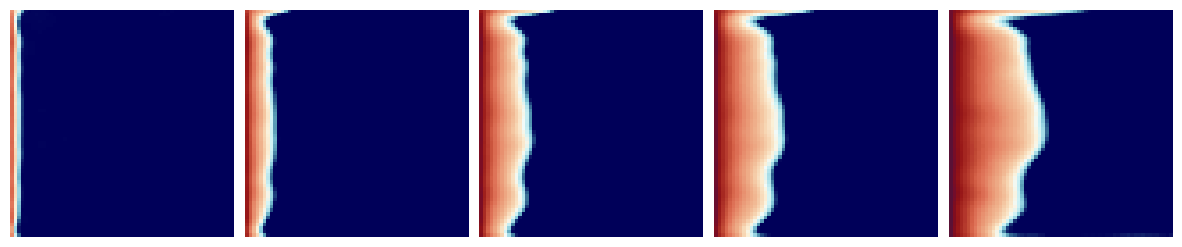

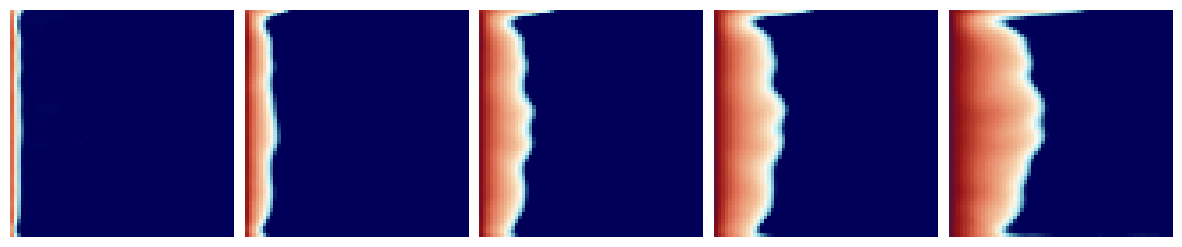

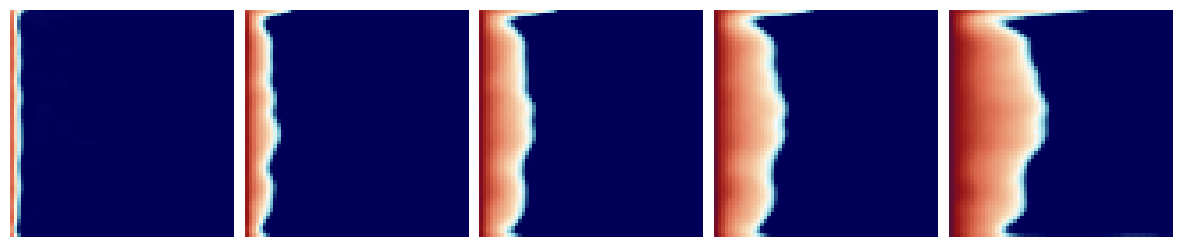

In [62]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_20[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs_sparse/UFNO_sparse(20)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_41[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs_sparse/UFNO_sparse(41)_Sg.pdf', bbox_inches='tight')

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    ax[i].imshow(ufno_pred_123[:, :-1, t], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('forward_outputs/figs_sparse/UFNO_sparse(123)_Sg.pdf', bbox_inches='tight')

In [64]:
gen_list = [sparse20[..., 1], sparse41[..., 1], sparse123[..., 1]]
ufno_list = [ufno_pred_20, ufno_pred_41, ufno_pred_123]
def metric_wrapper():
    ssim_gen_list = []
    rmse_gen_list = []
    ssim_ufno_list = []
    rmse_ufno_list = []
    for gen, ufno_pred in zip(gen_list, ufno_list):
        ssim_gen = compute_temporal_ssim(ref, gen)
        rmse_gen = compute_temporal_rmse(ref, gen)
        ssim_ufno = compute_temporal_ssim(ref, ufno_pred)
        rmse_ufno = compute_temporal_rmse(ref, ufno_pred)

        ssim_gen_list.append(ssim_gen)
        rmse_gen_list.append(rmse_gen)
        ssim_ufno_list.append(ssim_ufno)
        rmse_ufno_list.append(rmse_ufno)
    ssim_gen_list = np.array(ssim_gen_list)
    rmse_gen_list = np.array(rmse_gen_list)
    ssim_ufno_list = np.array(ssim_ufno_list)
    rmse_ufno_list = np.array(rmse_ufno_list)
    print(f"SSIM for CoNFiLD-geo shape: {ssim_gen_list.shape}, UFNO shape: {ssim_ufno_list.shape}")
    print(f"RMSE for CoNFiLD-geo shape: {rmse_gen_list.shape}, UFNO shape: {rmse_ufno_list.shape}")
    return ssim_gen_list, rmse_gen_list, ssim_ufno_list, rmse_ufno_list

ssim_gen_list, rmse_gen_list, ssim_ufno_list, rmse_ufno_list = metric_wrapper()

Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
Computing SSIM for CoNFiLD-geo
Computing SSIM for CoNFiLD-geo
Computing SSIM for UFNO
Computing SSIM for UFNO
SSIM for CoNFiLD-geo shape: (3, 10, 64), UFNO shape: (3, 64)
RMSE for CoNFiLD-geo shape: (3, 10, 64), UFNO shape: (3, 64)


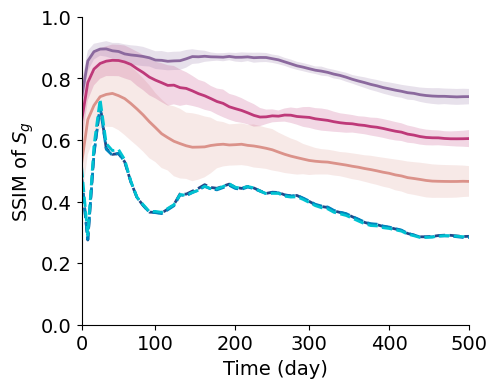

In [66]:
colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = ['CoNFiLD-geo (0.05%)', 'CoNFiLD-geo (1%)', 'CoNFiLD-geo (3%)']
labels_ufno = ['U-FNO (0.05%)', 'U-FNO (1%)', 'U-FNO (3%)']

plt.figure(figsize=(5, 4))

for i in range(3):
    plot_perm_mean_std(ssim_gen_list[i], colors_gen[i], labels_gen[i])
    plt.plot(range(64), ssim_ufno_list[i], color=colors_ufno[i], linewidth=2, label=labels_ufno[i], ls='--')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(bottom=0, top=1)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('SSIM of $S_g$', fontsize=14)
plt.savefig('forward_outputs/figs_sparse/sparse_ssim_sg.pdf', bbox_inches='tight')

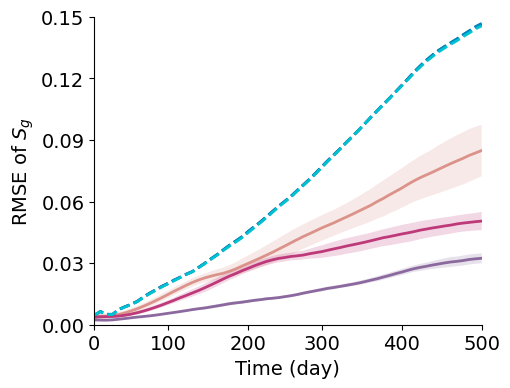

In [76]:
colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = ['CoNFiLD-geo (0.05%)', 'CoNFiLD-geo (1%)', 'CoNFiLD-geo (3%)']
labels_ufno = ['U-FNO (0.05%)', 'U-FNO (1%)', 'U-FNO (3%)']

plt.figure(figsize=(5, 4))

for i in range(3):
    plot_perm_mean_std(rmse_gen_list[i], colors_gen[i], labels_gen[i])
    plt.plot(range(64), rmse_ufno_list[i], color=colors_ufno[i], linewidth=2, label=labels_ufno[i], ls='--')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(0, 0.15)
plt.yticks([0, 0.03, 0.06, 0.09, 0.12, 0.15], fontsize=14)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('RMSE of $S_g$', fontsize=14)
plt.savefig('forward_outputs/figs_sparse/sparse_rmse_sg.pdf', bbox_inches='tight')

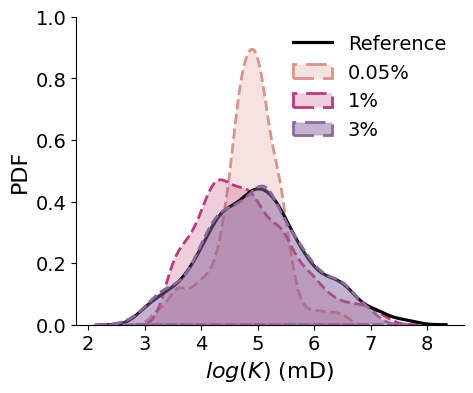

In [79]:
sr4_k_hist = np.mean(sparse20_k, axis=0)
sr8_k_hist = np.mean(sparse41_k, axis=0)
sr16_k_hist = np.mean(sparse123_k, axis=0)

plt.figure(figsize=(5, 4))
colors = ['#0499b4', '#00468c', '#ae002a']
import seaborn as sns
sns.kdeplot(ref[0, :, :, -1].flatten(), color='black', label='Reference', linewidth=2.3, fill=False, ls='-', alpha=1)
sns.kdeplot(sr4_k_hist.flatten(), color=colors_gen[0], label='0.05%', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr8_k_hist.flatten(), color=colors_gen[1], label='1%', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr16_k_hist.flatten(), color=colors_gen[2], label='3%', linewidth=2, fill=True, ls='--', zorder=10, alpha=0.5)
# plt.xlim(1.5, 6.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 1.0)
plt.yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize=14)
plt.xlabel('$log(K)$ (mD)', fontsize=16)
plt.ylabel('PDF', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(fontsize=14, frameon=False, loc='upper right')
plt.savefig('forward_outputs/figs_sparse/sparse_k_hist.pdf', bbox_inches='tight')
plt.show()

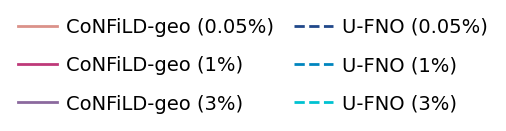

In [80]:
from matplotlib.lines import Line2D

colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_ufno = ["#20488a", "#0085be", "#00c2d1"]

labels_gen = ['CoNFiLD-geo (0.05%)', 'CoNFiLD-geo (1%)', 'CoNFiLD-geo (3%)']
labels_ufno = ['U-FNO (0.05%)', 'U-FNO (1%)', 'U-FNO (3%)']

legend_elements = [
    # CoNFiLD-geo
    Line2D([0], [0], color=colors_gen[0], lw=2, ls='-', label=labels_gen[0]),
    Line2D([0], [0], color=colors_gen[1], lw=2, ls='-', label=labels_gen[1]),
    Line2D([0], [0], color=colors_gen[2], lw=2, ls='-', label=labels_gen[2]),
    # ufno
    Line2D([0], [0], color=colors_ufno[0], lw=2, ls='--', label=labels_ufno[0]),
    Line2D([0], [0], color=colors_ufno[1], lw=2, ls='--', label=labels_ufno[1]),
    Line2D([0], [0], color=colors_ufno[2], lw=2, ls='--', label=labels_ufno[2])
]

fig, ax = plt.subplots(figsize=(6, 1))
ax.axis('off')

# 添加图例：3 行 2 列
fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=2,
    frameon=False,
    handlelength=2,
    handletextpad=0.5,
    columnspacing=1,
    labelspacing=1,
    fontsize=14,
)

# plt.tight_layout()
plt.savefig('forward_outputs/figs_sparse/sparse_ssim_rmse_legends.pdf', bbox_inches='tight')
plt.show()

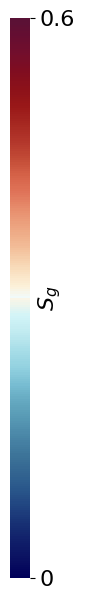

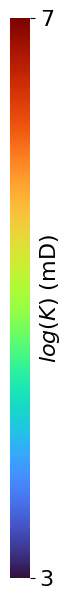

In [33]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.6)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([0, 0.6])
cbar.ax.set_yticklabels(["0", "0.6"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("forward_outputs/figs/vertical_sg_legend.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=3, vmax=7)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([3, 7])
cbar.ax.set_yticklabels(["3", "7"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("forward_outputs/figs/vertical_k_legend.pdf", bbox_inches='tight')
plt.show()